# Audit du référentiel TVA — Analyse et restitution

**Auteur : Amaury Ducoulombier | Étude des 17 et 18 novembre 2026**

Ce notebook présente les phases 2 à 4 du brief : nettoyage, collecte expliquée et réconciliation. L’exploration initiale figure dans [Exploration.ipynb](Exploration.ipynb).

**Reproduction :** exécuter depuis le dossier Notebook avec les fichiers du dépôt. Le mode par défaut relit les réponses VIES archivées, sans nouvel appel. Le script indépendant collecte_vies.py réalise la collecte ; ses résultats doivent être disponibles pour la réconciliation. Activer relancer_essais volontairement relance les essais historiques et peut modifier leurs sorties ; cela n’actualise pas automatiquement les archives.

# Phase 2 — Nettoyer, filtrer et chiffrer l’entonnoir


## 2.1 — Importer le module fourni


In [2]:
import json
from pathlib import Path

# Mode de restitution : ne pas refaire les appels VIES.
relancer_essais = False
racine = Path.cwd()
if not (racine / "starter-kit").exists():
    racine = racine.parent

with open(racine / "resultats" / "essais_manuels_vies.json", encoding="utf-8") as fichier:
    essais_manuels = json.load(fichier)

import sys
sys.path.insert(0, "../starter-kit")

from validation_structure import normaliser, valider


Les exemples du README permettent de vérifier l’import des fonctions fournies.


In [3]:
print(normaliser(" fr 27 552032534 "))
print(valider("FR27552032534"))
print(valider("FR99552032534"))
print(valider("XX12345678"))

FR27552032534
(True, 'ok')
(False, 'cle_invalide')
(False, 'pays_non_couvert')


## 2.2 — Charger les données

Le CSV est la source de référence retenue après la comparaison menée en phase 1. Le chargement conserve les valeurs sous forme de texte.


In [4]:
import pandas as pd

df = pd.read_csv(
    "../starter-kit/data/numeros_tva.csv",
    dtype=str,
    keep_default_na=False
)

print("Nombre de lignes :", len(df))
display(df.head())

Nombre de lignes : 10000


,id,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
0,1,Nord Technologies GmbH,DK,DK73224645,2025-07-27,portail_client
1,2,Solaris Technologies SARL,PT,PT787327239,2024-03-29,reprise_erp
2,3,Verso Consulting NV,LU,LU71043234,2024-02-16,crm
3,4,Lumen Distribution Sp. z o.o.,SE,SE.751298146001,2024-02-27,import_fournisseur
4,5,Textil Services Oy,NL,NL505862176B88,2025-04-14,crm


## 2.3 — Traiter les absences

Les six formes d’absence observées en phase 1 sont traitées explicitement. `NU.LL` est considéré comme une absence probable : cette interprétation est une décision de nettoyage, pas une règle du module fourni.


In [5]:
masque_absence = df["numero_tva"].isin(
    ["", " ", "-", "N/A", "null", "NU.LL"]
)

print("Nombre d'absences :", masque_absence.sum())

Nombre d'absences : 261


## 2.4 — Normaliser les numéros

La fonction `normaliser()` du module fourni est appliquée après conversion des marqueurs d’absence en chaînes vides. La colonne brute est conservée.


In [6]:
# Conserver les données brutes et travailler dans une copie
nettoyage = df.copy()

nettoyage["numero_normalise"] = (
    df["numero_tva"].mask(masque_absence, "").map(normaliser)
)

display(nettoyage[["numero_tva", "numero_normalise"]].head(15))

,numero_tva,numero_normalise
0,DK73224645,DK73224645
1,PT787327239,PT787327239
2,LU71043234,LU71043234
3,SE.751298146001,SE751298146001
4,NL505862176B88,NL505862176B88
5,DK61530843,DK61530843
6,NL505862176B88,NL505862176B88
7,SE.314125231601,SE314125231601
8,DK48646344,DK48646344
9,BE1997422119,BE1997422119


## 2.5 — Définir et compter les doublons

**Définition retenue :** deux lignes sont des doublons de numéro lorsqu’elles portent le même numéro normalisé non vide.


In [7]:
# Exclure les absences du comptage des doublons
numeros_non_vides = nettoyage[
    nettoyage["numero_normalise"] != ""
]

# Compter les répétitions après la première occurrence
doublons = numeros_non_vides["numero_normalise"].duplicated()

print("Lignes avec un numéro non vide :", len(numeros_non_vides))
print("Répétitions supplémentaires :", doublons.sum())
print("Numéros uniques :", numeros_non_vides["numero_normalise"].nunique())

Lignes avec un numéro non vide : 9739
Répétitions supplémentaires : 438
Numéros uniques : 9301


Le tableau suivant conserve une ligne par numéro normalisé non vide, sans supprimer les lignes du tableau d’origine.


In [8]:
numeros_uniques = numeros_non_vides.drop_duplicates(
    subset="numero_normalise"
).copy()

print("Nombre de numéros uniques à contrôler :", len(numeros_uniques))

Nombre de numéros uniques à contrôler : 9301


## 2.6 — Contrôler la structure

**Source :** `starter-kit/validation_structure.py`. La fonction `valider()` est appliquée aux 9 301 numéros uniques. Elle contrôle le format et la clé selon le pays. Le motif `cle_invalide` peut désigner une longueur incorrecte, des caractères non conformes ou une mauvaise clé. Un résultat `ok` ne prouve pas l’existence du numéro dans VIES.


In [9]:
resultats = numeros_uniques["numero_normalise"].map(valider)

numeros_uniques["structure_valide"] = resultats.str[0]
numeros_uniques["motif"] = resultats.str[1]

print(numeros_uniques["motif"].value_counts())

motif
ok                  5802
cle_invalide        2499
pays_non_couvert    1000
Name: count, dtype: int64


## 2.7 — Examiner les numéros non couverts

Les 1 000 numéros classés `pays_non_couvert` sont examinés pour distinguer les préfixes non couverts des préfixes absents.


In [10]:
non_couverts = numeros_uniques[
    numeros_uniques["motif"] == "pays_non_couvert"
]

print("Deux premiers caractères et effectifs :")
print(non_couverts["numero_normalise"].str[:2].value_counts())

display(
    non_couverts[
        ["pays_declare", "numero_tva", "numero_normalise"]
    ].head(20)
)

Deux premiers caractères et effectifs :
numero_normalise
ZZ    108
QQ    105
GB    102
UK     99
XX     86
     ... 
49      2
32      1
61      1
96      1
82      1
Name: count, Length: 104, dtype: int64


,pays_declare,numero_tva,numero_normalise
16,GB,GB0749640348,GB0749640348
34,ZZ,ZZ23140153,ZZ23140153
68,GB,GB17652291,GB17652291
79,UK,UK227979060,UK227979060
119,FR,58560322811,58560322811
134,NL,396904956B68,396904956B68
145,UK,UK190500864B18,UK190500864B18
151,ZZ,ZZ06520766,ZZ06520766
162,IT,38486825359,38486825359
180,IT,33139885439,33139885439


### Repérer les préfixes absents

Les numéros commençant par un chiffre sont examinés séparément avant toute décision de reconstruction.


In [11]:
sans_prefixe = non_couverts[
    non_couverts["numero_normalise"].str.match(r"^[0-9]")
]

print("Numéros commençant par un chiffre :", len(sans_prefixe))
print(sans_prefixe["pays_declare"].value_counts())

Numéros commençant par un chiffre : 500
pays_declare
NL    60
SE    56
PL    54
PT    52
DK    49
BE    47
FI    47
IT    46
FR    45
LU    44
Name: count, dtype: int64


Les 1 000 numéros non couverts comprennent 500 préfixes non contrôlés et 500 numéros commençant par un chiffre, associés aux dix pays couverts. Une reconstruction est étudiée sans remplacer les valeurs brutes.


In [12]:
sans_prefixe = sans_prefixe.copy()

sans_prefixe["numero_propose"] = (
    sans_prefixe["pays_declare"] + sans_prefixe["numero_normalise"]
)

print(sans_prefixe["numero_propose"].map(valider).value_counts())

numero_propose
(True, ok)    500
Name: count, dtype: int64


Les 500 propositions obtenues par ajout du pays déclaré passent les contrôles du module. Cette conformité ne prouve ni que le pays ajouté est correct ni que le numéro existe. Les propositions restent distinctes des valeurs brutes. Les contrôles suivants recherchent les doublons après cette transformation.


### Vérifier les doublons après reconstruction

Les 500 propositions sont comparées aux 5 802 numéros initialement conformes.


In [13]:
numeros_ok = numeros_uniques.loc[
    numeros_uniques["motif"] == "ok",
    "numero_normalise"
]

deja_presents = sans_prefixe["numero_propose"].isin(numeros_ok)

print("Numéros reconstruits déjà présents :", deja_presents.sum())
print("Numéros reconstruits non présents :", (~deja_presents).sum())

Numéros reconstruits déjà présents : 0
Numéros reconstruits non présents : 500


Aucun des 500 numéros reconstruits ne figure parmi les 5 802 numéros initialement conformes. Le contrôle suivant recherche les répétitions entre propositions. La reconstruction reste une hypothèse documentée.


Contrôle des doublons entre les 500 propositions.


In [14]:
print(
    "Doublons entre les propositions :",
    sans_prefixe["numero_propose"].duplicated().sum()
)

Doublons entre les propositions : 0


## 2.8 — Documenter le traitement des familles


| Famille | Traitement retenu |
|---|---|
| 261 absences | Conserver les lignes et demander le numéro ; aucun appel VIES |
| 438 répétitions supplémentaires | Conserver les liens avec les lignes d’origine ; éviter les appels en double |
| 5 802 numéros `ok` | Candidats à une vérification VIES ; pas encore déclarés valides |
| 2 499 `cle_invalide` | Écarter des appels en l’état et demander une correction : format ou clé rejeté par le module |
| 500 préfixes non couverts | Conserver à examiner séparément ; ne pas les déclarer invalides sur ce seul motif |
| 500 numéros reconstruits | Conserver comme propositions distinctes, avec le pays ajouté et la justification ; vérification VIES envisagée sous cette hypothèse |


Les 261 absences sont conservées dans les lignes d’origine et exclues des numéros uniques à contrôler. Le motif vide ne figure donc pas dans ce comptage. Aucun numéro unique non vide ne reçoit le motif trop_court, qui désigne moins de quatre caractères après normalisation. L’absence de ces motifs dans le tableau ne signifie pas qu’ils sont ignorés.


## 2.9 — Construire l’entonnoir

Aucun doublon supplémentaire n’est observé entre les propositions. Le tableau présente les étapes et l’ajout des propositions aux candidats initialement conformes.


In [15]:
candidats_vies = pd.concat([
    numeros_ok,
    sans_prefixe["numero_propose"]
]).drop_duplicates()

entonnoir = pd.DataFrame({
    "Etape": [
        "Lignes initiales",
        "Numéros non vides après normalisation",
        "Numéros uniques avant reconstruction",
        "Structures conformes initialement",
        "Candidats après reconstruction proposée"
    ],
    "Nombre": [
        len(df),
        len(numeros_non_vides),
        len(numeros_uniques),
        len(numeros_ok),
        len(candidats_vies)
    ]
})

display(entonnoir)

print("Appels économisés :", len(df) - len(candidats_vies))

,Etape,Nombre
0,Lignes initiales,10000
1,Numéros non vides après normalisation,9739
2,Numéros uniques avant reconstruction,9301
3,Structures conformes initialement,5802
4,Candidats après reconstruction proposée,6302


Appels économisés : 3698


L’inclusion des 500 reconstructions porte les candidats à 6 302, contre 5 802 sans cette hypothèse. Par rapport à 10 000 appels, cela évite 3 698 appels, soit 36,98 %. La dernière ligne du tableau est un ajout de propositions, pas une réduction supplémentaire.


## 2.10 — Mesurer les temps de réponse de VIES


Sélection des deux premiers numéros initialement conformes par pays, sans reconstruction, pour mesurer les temps de réponse.


In [16]:
echantillon_test = (
    numeros_uniques[numeros_uniques["motif"] == "ok"]
    .groupby("pays_declare")
    .head(2)
)

display(echantillon_test[["pays_declare", "numero_normalise"]])

,pays_declare,numero_normalise
1,PT,PT787327239
2,LU,LU71043234
3,SE,SE751298146001
5,DK,DK61530843
7,SE,SE314125231601
8,DK,DK48646344
9,BE,BE1997422119
10,FI,FI84564443
11,NL,NL767957817B57
15,NL,NL962988030B37


Le résultat est conforme à cette étape : 20 numéros uniques, soit 2 pour chacun des 10 pays couverts.

Ils proviennent tous du groupe ok, sans reconstruction de préfixe. Ils passent donc les contrôles du module fourni, mais leur validité réelle reste à vérifier avec VIES.

Cette sélection convient pour les essais de temps de réponse demandés par le brief. Elle n’est pas représentative du référentiel : ce sont les deux premiers numéros conformes de chaque pays.


### Collecter et conserver les vingt mesures

**Sources :** URL du README et consignes de temporisation du brief. La boucle et la sauvegarde sont du code complémentaire ; le module fourni sert au filtrage structurel.

Chaque tentative est sauvegardée, y compris en cas d’erreur réseau. Les numéros enregistrés sont sautés à la relance ; les erreurs ne sont pas automatiquement retentées et ne prouvent pas l’invalidité du numéro. La pause est exclue de la durée mesurée.

Les deux premières réponses sont préservées avec des durées archivées arrondies à deux décimales (`duree_arrondie=True`). Ces essais ne remplacent pas le script avec journal de phase 3.


In [17]:
import json
import time
import requests
from pathlib import Path
from datetime import datetime, timezone

racine = Path.cwd()
if not (racine / "starter-kit").exists():
    racine = racine.parent

fichier_mesures = racine / "resultats" / "mesures_vies.json"
fichier_mesures.parent.mkdir(exist_ok=True)

# Restaurer les résultats après fermeture du noyau.
if fichier_mesures.exists():
    mesures = json.loads(fichier_mesures.read_text(encoding="utf-8"))
else:
    mesures = []

deja_mesures = {m["numero"] for m in mesures}

for numero in echantillon_test["numero_normalise"]:
    if numero in deja_mesures:
        print(numero, ": déjà enregistré, appel sauté")
        continue

    if not relancer_essais:
        raise RuntimeError("Mesure archivée manquante : activer volontairement les essais réseau.")

    time.sleep(1)
    resultat = {
        "numero": numero,
        "pays": numero[:2],
        "date_appel": datetime.now(timezone.utc).isoformat(),
        "code_http": None,
        "duree_secondes": None,
        "duree_arrondie": False,
        "reponse_complete": None,
        "erreur": None
    }
    url = (
        "https://ec.europa.eu/taxation_customs/vies/rest-api/"
        f"ms/{numero[:2]}/vat/{numero[2:]}"
    )
    debut = time.perf_counter()
    try:
        reponse = requests.get(url, timeout=30)
        resultat["duree_secondes"] = time.perf_counter() - debut
        resultat["code_http"] = reponse.status_code
        resultat["reponse_complete"] = reponse.text
    except requests.RequestException as erreur:
        resultat["duree_secondes"] = time.perf_counter() - debut
        resultat["erreur"] = str(erreur)

    mesures.append(resultat)

    # Sauver chaque tentative avant de passer au numéro suivant.
    temporaire = fichier_mesures.with_suffix(".tmp")
    temporaire.write_text(
        json.dumps(mesures, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )
    temporaire.replace(fichier_mesures)
    deja_mesures.add(numero)

    print(numero, "— HTTP :", resultat["code_http"])
    print(resultat["reponse_complete"] or resultat["erreur"])

selection = set(echantillon_test["numero_normalise"])
mesures_test = pd.DataFrame([
    m for m in mesures if m["numero"] in selection
])
display(mesures_test)
print("Nombre de mesures pour la sélection :", len(mesures_test))



PT787327239

 : déjà enregistré, appel sauté
LU71043234 : déjà enregistré, appel sauté
SE751298146001 : déjà enregistré, appel sauté
DK61530843 : déjà enregistré, appel sauté
SE314125231601 : déjà enregistré, appel sauté
DK48646344 : déjà enregistré, appel sauté
BE1997422119 : déjà enregistré, appel sauté
FI84564443 : déjà enregistré, appel sauté
NL767957817B57 : déjà enregistré, appel sauté
NL962988030B37 : déjà enregistré, appel sauté
BE1628475293 : déjà enregistré, appel sauté
FR63432337650 : déjà enregistré, appel sauté
LU45829332 : déjà enregistré, appel sauté
FR58658124710 : déjà enregistré, appel sauté
PT682102423 : déjà enregistré, appel sauté
FI77720866 : déjà enregistré, appel sauté
PL7963612947 : déjà enregistré, appel sauté
PL4372432809 : déjà enregistré, appel sauté
IT97133603924 : déjà enregistré, appel sauté
IT62989143151 : déjà enregistré, appel sauté


,numero,pays,date_appel,code_http,duree_secondes,duree_arrondie,reponse_complete,erreur
0,PT787327239,PT,2026-11-17T15:41:58.615Z,200,0.420000,True,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
1,LU71043234,LU,2026-11-17T15:48:58.965Z,200,0.220000,True,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
2,SE751298146001,SE,2026-11-17T16:01:38.436808+00:00,200,0.507767,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
3,DK61530843,DK,2026-11-17T16:01:39.947008+00:00,200,9.794842,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
4,SE314125231601,SE,2026-11-17T16:01:50.744778+00:00,200,0.725449,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
5,DK48646344,DK,2026-11-17T16:01:52.478023+00:00,200,11.189498,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
6,BE1997422119,BE,2026-11-17T16:02:04.674983+00:00,200,6.606852,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
7,FI84564443,FI,2026-11-17T16:02:12.287787+00:00,200,0.338177,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
8,NL767957817B57,NL,2026-11-17T16:02:13.628250+00:00,200,1.793792,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None
9,NL962988030B37,NL,2026-11-17T16:02:16.425528+00:00,200,1.356404,False,"{\n ""isValid"" : false,\n ""requestDate"" : ""20...",None


Nombre de mesures pour la sélection : 20


### Décrire le centre, la dispersion et les extrêmes


In [18]:
print(mesures_test["duree_secondes"].describe().round(2))

count    20.00
mean      1.79
std       3.31
min       0.13
25%       0.21
50%       0.41
75%       0.88
max      11.19
Name: duree_secondes, dtype: float64


Le calcul pandas describe() répond à la description demandée par le brief : 20 mesures, moyenne de 1,79 s, médiane de 0,41 s, écart-type de 3,31 s, minimum de 0,13 s et maximum de 11,19 s. Les quartiles sont 0,21 s et 0,88 s. Les durées excluent la pause. Quelques appels longs tirent la moyenne vers le haut. Ces mesures incluent les réponses contenant des erreurs du service.


### Comparer les durées moyennes par pays


In [19]:
# Temps de réponse moyen par pays, en secondes
moyenne_par_pays = mesures_test.groupby("pays")["duree_secondes"].mean()

print(moyenne_par_pays.round(2))

pays
BE     3.37
DK    10.49
FI     0.33
FR     0.17
IT     0.14
LU     0.24
NL     1.58
PL     0.42
PT     0.52
SE     0.62
Name: duree_secondes, dtype: float64


Le Danemark présente la moyenne la plus élevée (**10,49 s**), suivi de la Belgique (**3,37 s**) et des Pays-Bas (**1,58 s**). Les autres pays restent sous une seconde en moyenne.

**Limite :** deux appels seulement ont été mesurés par pays. Les réponses rapides de la France comprennent des erreurs du service. Une réponse rapide ne signifie pas une vérification réussie.


## 2.11 — Estimer la durée d’une campagne

Le premier calcul porte sur 10 000 appels avec une seconde de pause par appel. Il s’agit uniquement d’une estimation : aucune requête n’est lancée.


In [20]:
# Moyenne exacte des temps mesurés
temps_moyen = mesures_test["duree_secondes"].mean()

# Une seconde de pause avant chaque appel
duree_totale = 10000 * (temps_moyen + 1)

print("Durée estimée en heures :", round(duree_totale / 3600, 2))

Durée estimée en heures : 7.74


Estimation pour les 6 302 candidats sous l’hypothèse des 500 reconstructions. Les calculs ajoutent une seconde de pause par appel et ne lancent aucune requête.

### Limites de l’estimation

Les estimations reposent sur vingt mesures, seulement deux par pays, sélectionnées pour explorer le service et non pour représenter les candidats. Elles incluent des réponses contenant des erreurs du service et deux durées archivées arrondies à deux décimales. Elles supposent des conditions similaires, sans nouvelle tentative après erreur. Elles donnent un ordre de grandeur, pas une durée garantie. Deux observations par pays ne démontrent pas une performance durable du service national.


In [21]:
# Nombre de candidats calculé dans l'entonnoir
nombre_candidats = len(candidats_vies)

# Estimation avec une seconde de pause par appel
duree_nettoyee = nombre_candidats * (temps_moyen + 1)

print("Nombre de candidats :", nombre_candidats)
print("Durée estimée en heures :", round(duree_nettoyee / 3600, 2))

# Comparer avec l'estimation pour 10 000 appels
temps_economise = duree_totale - duree_nettoyee

print("Temps économisé en heures :", round(temps_economise / 3600, 2))

Nombre de candidats : 6302
Durée estimée en heures : 4.88
Temps économisé en heures : 2.86


## 2.12 — Interpréter les réponses du service

**Sources :** le README demande de lire tous les champs ; le brief impose de distinguer les erreurs du service de l’invalidité des numéros, même avec un code HTTP 200.


Lecture du champ userError dans la première réponse sauvegardée.


In [22]:
# Lire la première réponse sauvegardée
texte = mesures_test["reponse_complete"].iloc[0]
reponse_json = json.loads(texte)

# Afficher le champ qui précise le résultat du service
print(reponse_json["userError"])

INVALID


La première réponse contient userError=INVALID, un verdict négatif. Le comptage suivant examine le même champ dans les vingt réponses sauvegardées.


In [23]:
# Rassembler les résultats du service dans une liste
resultats_service = []

for texte in mesures_test["reponse_complete"]:
    reponse_json = json.loads(texte)
    resultats_service.append(reponse_json["userError"])

# Compter chaque résultat
print(pd.Series(resultats_service).value_counts())

INVALID                  17
MS_MAX_CONCURRENT_REQ     3
Name: count, dtype: int64


Les vingt essais produisent **17 réponses `INVALID`** et **3 réponses `MS_MAX_CONCURRENT_REQ`**. Les premières correspondent à des verdicts négatifs aux dates de consultation ; les secondes restent non tranchées malgré HTTP 200 et `isValid=false`.

Un défaut du service n’est pas un défaut du numéro. Cette sélection d’essai n’étant pas représentative, les comptes ne sont pas extrapolés aux 10 000 lignes.


## 2.13 — Conclusion de la phase 2

Le nettoyage conduit à **6 302 candidats** sous l’hypothèse des 500 reconstructions, soit **3 698 appels évités**. Les vingt essais présentent une durée moyenne de 1,79 s et une médiane de 0,41 s. Avec une seconde de pause par appel, la campagne est estimée à 4,88 heures, hors nouvelles tentatives. Les essais produisent 17 verdicts négatifs et 3 cas non tranchés liés au service.


# Phase 3 — Essais et collecte VIES


## 3.1 — Réaliser les essais manuels

Le brief prévoit trois essais : un numéro connu valide, une clé fausse et un numéro inventé.

### Essai de la référence du README

Le premier essai utilise la référence française du README. Sa conformité structurelle ne garantit pas un verdict positif actuel. Un cas positif est documenté ensuite avec la réponse sauvegardée de `DK50549151`.


In [24]:
import requests

# Exemple d'appel fourni dans le README
url = (
    "https://ec.europa.eu/taxation_customs/vies/"
    "rest-api/ms/FR/vat/27552032534"
)

# Les réponses archivées sont lues par défaut, sans nouvel appel.
if relancer_essais:
    reponse_test = requests.get(url, timeout=30)
    print("Code HTTP :", reponse_test.status_code)
    print(reponse_test.text)
else:
    numero_archive = "FR" + url.rsplit("/", 1)[-1]
    reponse_archive = essais_manuels[numero_archive]
    print("Réponse archivée — aucun appel réseau")
    print("Code HTTP :", reponse_archive["code_http"])
    print(reponse_archive["reponse_complete"])


Réponse archivée — aucun appel réseau
Code HTTP : 200
{
  "isValid" : false,
  "requestDate" : "2026-11-18T09:45:52.128Z",
  "userError" : "MS_MAX_CONCURRENT_REQ",
  "name" : "---",
  "address" : "---",
  "requestIdentifier" : "",
  "originalVatNumber" : "27552032534",
  "vatNumber" : "27552032534",
  "viesApproximate" : {
    "name" : "---",
    "street" : "---",
    "postalCode" : "---",
    "city" : "---",
    "companyType" : "---",
    "matchName" : 3,
    "matchStreet" : 3,
    "matchPostalCode" : 3,
    "matchCity" : 3,
    "matchCompanyType" : 3
  }
}


Le service retourne HTTP 200, isValid=false et userError=MS_MAX_CONCURRENT_REQ. Cette limitation ne permet pas de trancher. La réponse est conservée comme exemple d’erreur technique ; le cas positif documenté plus bas provient de la collecte.


### Essai d’une clé volontairement fausse

**Source :** le README fournit `FR99552032534` comme exemple renvoyant `cle_invalide`. L’appel manuel demandé par le brief permet d’observer la réponse du service. Ce numéro est exclu de la collecte normale.


In [25]:
import time

# Vérification avec le module fourni
print(valider("FR99552032534"))

# Espacer les essais
if relancer_essais:
    time.sleep(5)

url = (
    "https://ec.europa.eu/taxation_customs/vies/"
    "rest-api/ms/FR/vat/99552032534"
)

# Les réponses archivées sont lues par défaut, sans nouvel appel.
if relancer_essais:
    reponse_test = requests.get(url, timeout=30)
    print("Code HTTP :", reponse_test.status_code)
    print(reponse_test.text)
else:
    numero_archive = "FR" + url.rsplit("/", 1)[-1]
    reponse_archive = essais_manuels[numero_archive]
    print("Réponse archivée — aucun appel réseau")
    print("Code HTTP :", reponse_archive["code_http"])
    print(reponse_archive["reponse_complete"])


(False, 'cle_invalide')
Réponse archivée — aucun appel réseau
Code HTTP : 200
{
  "isValid" : false,
  "requestDate" : "2026-11-18T09:50:14.647Z",
  "userError" : "INVALID",
  "name" : "---",
  "address" : "---",
  "requestIdentifier" : "",
  "originalVatNumber" : "99552032534",
  "vatNumber" : "99552032534",
  "viesApproximate" : {
    "name" : "---",
    "street" : "---",
    "postalCode" : "---",
    "city" : "---",
    "companyType" : "---",
    "matchName" : 3,
    "matchStreet" : 3,
    "matchPostalCode" : 3,
    "matchCity" : 3,
    "matchCompanyType" : 3
  }
}


### Lecture de la réponse à la clé fausse

Le module renvoie cle_invalide et VIES renvoie INVALID. Le registre ne précise pas ici que la clé est la cause du rejet ; cette explication vient du contrôle local.

| Champ | Interprétation dans cette réponse |
|---|---|
| HTTP 200 | Réponse reçue, sans garantie de validité du numéro |
| isValid=false | À lire avec userError |
| userError=INVALID | Verdict négatif, distinct d’une limitation du service |
| requestDate | Date de consultation renvoyée par VIES ; verdict daté |
| name et address | --- : aucune identité exploitable fournie ici |
| requestIdentifier | Champ de référence de demande vide dans cette réponse |
| originalVatNumber | Valeur initiale transmise sans préfixe pays |
| vatNumber | Valeur retenue dans la réponse, ici identique |
| viesApproximate | Informations et codes de rapprochement d’identité |
| matchName, matchStreet et autres codes | Tous valent 3 ; leur légende n’est pas établie par les ressources lues : aucune correspondance n’en est déduite |

HTTP 200 et isValid=false ne suffisent pas à décider : INVALID et MS_MAX_CONCURRENT_REQ conduisent à des traitements différents.


### Essai sur un numéro construit

Le premier numéro construit, FR40345678901, possède une clé incorrecte selon le module. La formule française fournie donne la clé 15 pour les neuf chiffres 345678901, soit FR15345678901. Les cellules suivantes conservent le premier essai, puis la correction et sa vérification. Construire un numéro ne garantit pas qu’il n’a jamais été attribué.


In [26]:
# Numéro construit pour l'essai
numero_invente = "FR40345678901"

# Contrôle avec le module fourni
print(valider(numero_invente))

if relancer_essais:
    time.sleep(5)

url = (
    "https://ec.europa.eu/taxation_customs/vies/"
    f"rest-api/ms/FR/vat/{numero_invente[2:]}"
)

# Les réponses archivées sont lues par défaut, sans nouvel appel.
if relancer_essais:
    reponse_test = requests.get(url, timeout=30)
    print("Code HTTP :", reponse_test.status_code)
    print(reponse_test.text)
else:
    numero_archive = "FR" + url.rsplit("/", 1)[-1]
    reponse_archive = essais_manuels[numero_archive]
    print("Réponse archivée — aucun appel réseau")
    print("Code HTTP :", reponse_archive["code_http"])
    print(reponse_archive["reponse_complete"])


(False, 'cle_invalide')
Réponse archivée — aucun appel réseau
Code HTTP : 200
{
  "isValid" : false,
  "requestDate" : "2026-11-18T09:58:15.187Z",
  "userError" : "INVALID",
  "name" : "---",
  "address" : "---",
  "requestIdentifier" : "",
  "originalVatNumber" : "40345678901",
  "vatNumber" : "40345678901",
  "viesApproximate" : {
    "name" : "---",
    "street" : "---",
    "postalCode" : "---",
    "city" : "---",
    "companyType" : "---",
    "matchName" : 3,
    "matchStreet" : 3,
    "matchPostalCode" : 3,
    "matchCity" : 3,
    "matchCompanyType" : 3
  }
}


Le premier essai produit cle_invalide localement et INVALID dans VIES. La clé 40 était incorrecte ; le calcul du module donne 15. La cellule suivante vérifie le numéro corrigé sans appel réseau.


Le numéro corrigé permet d’étudier la différence entre conformité structurelle et existence. Sa validation locale précède le nouvel essai VIES.


In [27]:
# Clé calculée selon la fonction _fr du module fourni
numero_invente = "FR15345678901"

print(valider(numero_invente))

(True, 'ok')


Essai VIES du numéro corrigé, conforme aux contrôles locaux.


In [28]:
# Espacer les essais
if relancer_essais:
    time.sleep(5)

# URL construite selon l'exemple du README
url = (
    "https://ec.europa.eu/taxation_customs/vies/"
    f"rest-api/ms/FR/vat/{numero_invente[2:]}"
)

# Les réponses archivées sont lues par défaut, sans nouvel appel.
if relancer_essais:
    reponse_test = requests.get(url, timeout=30)
    print("Code HTTP :", reponse_test.status_code)
    print(reponse_test.text)
else:
    numero_archive = "FR" + url.rsplit("/", 1)[-1]
    reponse_archive = essais_manuels[numero_archive]
    print("Réponse archivée — aucun appel réseau")
    print("Code HTTP :", reponse_archive["code_http"])
    print(reponse_archive["reponse_complete"])


Réponse archivée — aucun appel réseau
Code HTTP : 200
{
  "isValid" : false,
  "requestDate" : "2026-11-18T10:05:13.285Z",
  "userError" : "MS_MAX_CONCURRENT_REQ",
  "name" : "---",
  "address" : "---",
  "requestIdentifier" : "",
  "originalVatNumber" : "15345678901",
  "vatNumber" : "15345678901",
  "viesApproximate" : {
    "name" : "---",
    "street" : "---",
    "postalCode" : "---",
    "city" : "---",
    "companyType" : "---",
    "matchName" : 3,
    "matchStreet" : 3,
    "matchPostalCode" : 3,
    "matchCity" : 3,
    "matchCompanyType" : 3
  }
}


### Bilan des premiers essais

| Essai | Contrôle local | Réponse VIES enregistrée |
|---|---|---|
| FR27552032534, référence du README | Conforme | Non tranché : MS_MAX_CONCURRENT_REQ |
| FR99552032534, clé fausse | Rejeté | Verdict négatif INVALID |
| FR15345678901, numéro construit corrigé | Conforme | Non tranché : MS_MAX_CONCURRENT_REQ |

Les limitations du service ne sont pas des verdicts d’invalidité. Le cas positif est documenté plus bas par lecture de DK50549151, obtenu pendant la collecte. Il ne constitue pas rétroactivement un essai manuel positif antérieur à la boucle. Les réponses sont conservées avec cette limite, sans multiplier les tentatives pour forcer un résultat.


## 3.2 — Préparer la collecte indépendante

**Sources :** `collecte_vies.py` reprend l’URL du README et utilise `logging` conformément au brief. Le cours interne de logging était vide sur disque lors de sa consultation : aucun exemple de ce cours n’a été repris. La collecte, la sauvegarde et la reprise sont du code complémentaire au module de validation.


### Exporter les candidats et respecter l’ordre de lancement

1. Exécuter la préparation et l’export depuis le dossier `Notebook`.
2. Lancer `collecte_vies.py` depuis la racine du projet.
3. Revenir aux cellules de lecture et d’analyse des résultats.

Les lectures suivantes nécessitent `resultats/collecte_vies.json`, produit par le script.

**Limite de réexécution :** les essais réseau manuels précédents se relancent à chaque exécution et peuvent échouer si VIES est indisponible. Ils ne constituent pas une consultation des archives. Cette limite est également documentée dans le README.


In [29]:
from pathlib import Path

# Dossier de résultats à la racine du projet
dossier_resultats = Path("../resultats")
dossier_resultats.mkdir(exist_ok=True)

# Sauvegarder la liste des candidats sans doublons
candidats_vies.to_csv(
    dossier_resultats / "candidats_vies.csv",
    index=False,
    header=["numero_tva"]
)

print("Nombre de candidats sauvegardés :", len(candidats_vies))

Nombre de candidats sauvegardés : 6302


L’export contient **6 302 numéros uniques** dans une colonne `numero_tva`, sans valeur vide. Il inclut les 500 reconstructions proposées. Le script séparé charge cette liste, sélectionne son échantillon et conserve les réponses datées.

## 3.3 — Examiner un résultat positif sauvegardé


In [30]:
# Lire les résultats du script
with open("../resultats/collecte_vies.json", encoding="utf-8") as fichier:
    resultats_collecte = json.load(fichier)

# Afficher la réponse complète du numéro classé valide
for resultat in resultats_collecte:
    if resultat["numero"] == "DK50549151":
        print(resultat["date_appel"])
        print(resultat["reponse_complete"])

2026-11-18T10:58:57.685124+00:00
{
  "isValid" : true,
  "requestDate" : "2026-11-18T10:59:08.206Z",
  "userError" : "VALID",
  "name" : "Stûbert Hansen Arkitekter",
  "address" : "Møllevej 32A\n3140 Ålsgårde\n",
  "requestIdentifier" : "",
  "originalVatNumber" : "50549151",
  "vatNumber" : "50549151",
  "viesApproximate" : {
    "name" : "---",
    "street" : "---",
    "postalCode" : "---",
    "city" : "---",
    "companyType" : "---",
    "matchName" : 3,
    "matchStreet" : 3,
    "matchPostalCode" : 3,
    "matchCity" : 3,
    "matchCompanyType" : 3
  }
}


La réponse sauvegardée de DK50549151 confirme isValid=true et userError=VALID, avec un nom et une adresse. date_appel est le début d’appel enregistré par le script ; requestDate est renvoyée par VIES. La validité du numéro ne prouve pas sa correspondance avec le client : l’identité retournée nécessite un examen séparé. Le test d’interruption et de reprise a ensuite été effectué et ses traces sont conservées dans le journal.


## 3.4 — Présenter le bilan de la collecte

| Statut | Nombre | Part |
|---|---:|---:|
| Valide | 5 | 2,5 % |
| Invalide | 145 | 72,5 % |
| Non tranché | 50 | 25 % |

Le journal confirme une fin normale. Les 200 résultats sont uniques. Ces proportions concernent la sélection et ses dates d’appel, sans extrapolation directe aux 10 000 lignes. Les non tranchés restent distincts des invalides.


## 3.5 — Examiner le tirage de l’échantillon

Le script tire 200 numéros aléatoirement sans remise parmi les 6 302 candidats, avec `random_state=42`. Le tirage est reproductible pour un fichier d’entrée, un ordre et un environnement identiques. Cette population comprend les 500 reconstructions proposées et ne représente pas directement les 10 000 lignes brutes.

### Comparer la répartition par pays


Chargement des résultats actuels avant la comparaison.


In [31]:
# Lire les résultats sauvegardés
with open("../resultats/collecte_vies.json", encoding="utf-8") as fichier:
    resultats_collecte = json.load(fichier)

# Créer un tableau pandas
collecte = pd.DataFrame(resultats_collecte)

print("Nombre de résultats :", len(collecte))

Nombre de résultats : 200


Comptage des numéros interrogés par pays, puis calcul de leurs pourcentages.


In [32]:
# Répartition des 200 numéros interrogés
print(collecte["pays"].value_counts().sort_index())

pays
BE    19
DK    22
FI    17
FR    22
IT    21
LU    20
NL    24
PL    19
PT    19
SE    17
Name: count, dtype: int64


In [33]:
# Compter les numéros par pays
nombre_par_pays = collecte["pays"].value_counts()

# Calculer leur part parmi les 200 résultats
pourcentage_par_pays = nombre_par_pays / len(collecte) * 100

print(pourcentage_par_pays.sort_index().round(2))

pays
BE     9.5
DK    11.0
FI     8.5
FR    11.0
IT    10.5
LU    10.0
NL    12.0
PL     9.5
PT     9.5
SE     8.5
Name: count, dtype: float64


Calcul des proportions par pays parmi les 6 302 candidats.


In [34]:
# Extraire le pays depuis les deux premiers caractères
pays_candidats = candidats_vies.str[:2]

# Compter les candidats par pays
nombre_candidats_par_pays = pays_candidats.value_counts()

# Calculer les pourcentages
pourcentage_candidats = nombre_candidats_par_pays / len(candidats_vies) * 100

print(pourcentage_candidats.sort_index().round(2))

BE    10.22
DK     9.84
FI     9.22
FR    10.20
IT     9.58
LU    10.35
NL     9.82
PL    10.46
PT    10.31
SE    10.00
Name: count, dtype: float64


Comparaison des pourcentages des candidats et de l’échantillon.


In [35]:
comparaison_pays = pd.DataFrame({
    "Candidats (%)": pourcentage_candidats,
    "Echantillon (%)": pourcentage_par_pays
})

print(comparaison_pays.sort_index().round(2))

    Candidats (%)  Echantillon (%)
BE          10.22              9.5
DK           9.84             11.0
FI           9.22              8.5
FR          10.20             11.0
IT           9.58             10.5
LU          10.35             10.0
NL           9.82             12.0
PL          10.46              9.5
PT          10.31              9.5
SE          10.00              8.5


Le tableau montre que les dix pays sont présents dans l’échantillon, avec des proportions assez proches de celles des candidats.

L’écart le plus élevé concerne les Pays-Bas : 12 % dans l’échantillon contre 9,82 % des candidats, soit +2,18 points. La Suède présente un écart de −1,50 point.

L’échantillon couvre les dix pays, avec des écarts de répartition limités à environ 2,2 points. Cette proximité est rassurante sur la dimension pays, mais ne suffit pas à établir sa représentativité globale. Le tirage porte sur les 6 302 candidats, et non directement sur les 10 000 lignes.


### Présence des reconstructions dans l’échantillon

Ce contrôle complémentaire décrit la représentation des numéros issus d’une hypothèse de correction.


In [36]:
reconstruits = collecte["numero"].isin(sans_prefixe["numero_propose"])

print("Numéros reconstruits dans l'échantillon :", reconstruits.sum())

Numéros reconstruits dans l'échantillon : 11


Le comptage compare la part des propositions reconstruites dans la sélection et parmi les candidats.


L’échantillon contient 11 reconstructions sur 200, soit 5,5 %, contre 500 sur 6 302 candidats, soit 7,93 %. L’écart est de −2,43 points. Cette observation ne démontre pas à elle seule un biais du tirage.


## 3.6 — Définir l’utilisation dans le temps d’un verdict


Un verdict VIES décrit la situation à la date de consultation et ne garantit pas une validité permanente. Pour ce projet, nous proposons une nouvelle vérification avant une nouvelle facturation intracommunautaire ; un résultat vieux de six mois ne suffit donc pas à lui seul. La date et la réponse sont conservées pour assurer la traçabilité. Cette règle est une proposition de fonctionnement, pas une durée réglementaire fournie par le brief.

Notre script actuel évite les appels répétés dans une même campagne ; il ne gère pas encore le renouvellement des vérifications.


## 3.7 — Prévoir le réexamen des non tranchés

Les erreurs réseau, HTTP et les limitations du service ne prouvent pas l’invalidité du numéro. Les tentatives sont conservées avec le statut `non_tranche`, leur date et leur réponse ou erreur.

La reprise saute toutes les tentatives enregistrées, y compris les non tranchées. Leur réexamen doit être organisé dans une campagne distincte, après un délai, en conservant l’historique. Ce réexamen n’est pas automatisé dans le script actuel.

**Source :** cette règle de fonctionnement répond à la distinction exigée par le brief.


## 3.8 — Conclusion et transition vers la réconciliation

Les phases 2 et 3 conduisent à 6 302 candidats sous l’hypothèse des 500 reconstructions et à 200 résultats uniques : 5 valides, 145 invalides et 50 non tranchés. Les erreurs du service restent distinctes des verdicts négatifs. La reprise évite les appels dont les résultats sont enregistrés ; un appel interrompu avant sauvegarde peut être retenté.

La phase suivante rattache ces verdicts aux 10 000 lignes, explique les limites et prépare la restitution. Les lectures des essais utilisent les archives par défaut. Le script ne renouvelle pas automatiquement les verdicts et ne réexamine pas les non tranchés.


# Phase 4 — Analyser et restituer

## 4.1 — Préparer la réconciliation

L’objectif est de rattacher les résultats VIES aux lignes d’origine, en conservant les absences, les motifs structurels, les doublons et les reconstructions proposées. Un numéro non interrogé ne sera pas déclaré valide.

In [37]:
# Conserver toutes les lignes et les valeurs d'origine
reconciliation = nettoyage.copy()

print("Nombre de lignes à réconcilier :", len(reconciliation))

Nombre de lignes à réconcilier : 10000


### Préparer la clé de rapprochement

Le numéro normalisé d’origine est conservé. Une colonne séparée porte le numéro utilisé pour rechercher une réponse VIES ; son existence ne prouve pas qu’un appel a été effectué.


In [38]:
# Numéro servant à rechercher une réponse VIES
reconciliation["numero_verifie"] = reconciliation["numero_normalise"]

# Repérer toutes les lignes correspondant aux reconstructions proposées
a_reconstruire = reconciliation["numero_normalise"].isin(
    sans_prefixe["numero_normalise"]
)

print("Lignes concernées par une reconstruction :", a_reconstruire.sum())

Lignes concernées par une reconstruction : 532


Les 500 reconstructions portent sur des numéros uniques. Le nombre de lignes concernées peut être supérieur en présence de répétitions. Le pays déclaré reste une hypothèse à confirmer.


### Conserver la trace des reconstructions

La colonne prefixe_ajoute identifie les lignes dont le numéro de rapprochement comporte un pays ajouté.


In [39]:
# Indiquer les lignes concernées par l'hypothèse de reconstruction
reconciliation["prefixe_ajoute"] = a_reconstruire

# Ajouter le pays déclaré uniquement pour ces lignes
reconciliation.loc[a_reconstruire, "numero_verifie"] = (
    reconciliation.loc[a_reconstruire, "pays_declare"]
    + reconciliation.loc[a_reconstruire, "numero_normalise"]
)

# Afficher quelques exemples
display(
    reconciliation.loc[
        a_reconstruire,
        ["numero_tva", "numero_normalise", "numero_verifie", "prefixe_ajoute"]
    ].head()
)

,numero_tva,numero_normalise,numero_verifie,prefixe_ajoute
119,58560322811,58560322811,FR58560322811,True
134,396904956B68,396904956B68,NL396904956B68,True
162,38486825359,38486825359,IT38486825359,True
180,33139885439,33139885439,IT33139885439,True
188,88838354509,88838354509,IT88838354509,True


## 4.2 — Rattacher les réponses VIES

La jointure conserve les lignes d’origine et vérifie qu’un numéro n’a qu’une réponse dans la campagne.


In [40]:
# Garder le numéro, le statut et la date de chaque résultat
verdicts = collecte[["numero", "statut", "date_appel"]]

# Ajouter les résultats correspondants sans supprimer de ligne
reconciliation = reconciliation.merge(
    verdicts,
    left_on="numero_verifie",
    right_on="numero",
    how="left",
    validate="many_to_one"
)

print("Nombre de lignes après rapprochement :", len(reconciliation))
print("Lignes avec un résultat VIES :", reconciliation["statut"].notna().sum())

Nombre de lignes après rapprochement : 10000


Lignes avec un résultat VIES : 208


Le rapprochement conserve 10 000 lignes, dont 208 associées aux 200 réponses VIES. La différence provient des répétitions. Les verdicts sur les reconstructions concernent les numéros proposés.

### Ajouter les contrôles structurels

La fonction valider() du module fourni contrôle le numéro de rapprochement sans interroger VIES.


In [41]:
# Contrôler le numéro utilisé pour le rapprochement
controles = reconciliation["numero_verifie"].map(valider)

reconciliation["motif_structure"] = controles.str[1]

print(reconciliation["motif_structure"].value_counts())

motif_structure
ok                  6615
cle_invalide        2605
pays_non_couvert     519
vide                 261
Name: count, dtype: int64

## 4.3 — Définir les catégories de réconciliation

Les verdicts VIES sont repris ; les lignes sans réponse sont provisoirement non tranchées.


In [42]:
# Copier les statuts VIES
reconciliation["statut_final"] = reconciliation["statut"]

# Sans réponse VIES, le résultat reste provisoirement non tranché
reconciliation["statut_final"] = (
    reconciliation["statut_final"].fillna("non_tranche")
)

print(reconciliation["statut_final"].value_counts())

statut_final
non_tranche    9844
invalide        150
valide            6
Name: count, dtype: int64


Le classement provisoire compte 6 lignes valides selon VIES, 150 invalides selon VIES et 9 844 non tranchées. Les rejets structurels sont ensuite intégrés uniquement aux lignes sans réponse VIES.


In [43]:
# Repérer les formats ou clés rejetés par le module
rejet_structure = reconciliation["motif_structure"].isin(
    ["cle_invalide", "trop_court"]
)

# Modifier seulement les lignes sans réponse VIES
sans_reponse = reconciliation["statut"].isna()

reconciliation.loc[
    rejet_structure & sans_reponse,
    "statut_final"
] = "invalide"

print(reconciliation["statut_final"].value_counts())

statut_final
non_tranche    7239
invalide       2755
valide            6
Name: count, dtype: int64

### Expliquer chaque classement

Les motifs distinguent les verdicts VIES, les erreurs du service et les contrôles locaux.


In [44]:
# Motif provisoire pour les lignes sans réponse rattachée
reconciliation["motif_final"] = "a_preciser"

# Distinguer les trois résultats possibles de VIES
reconciliation.loc[
    reconciliation["statut"] == "valide", "motif_final"
] = "valide_vies"

reconciliation.loc[
    reconciliation["statut"] == "invalide", "motif_final"
] = "invalide_vies"

reconciliation.loc[
    reconciliation["statut"] == "non_tranche", "motif_final"
] = "vies_non_tranche"

print(reconciliation["motif_final"].value_counts())

motif_final
a_preciser          9792
invalide_vies        150
vies_non_tranche      52
valide_vies            6
Name: count, dtype: int64

Pour les lignes sans réponse VIES, le motif provient du module fourni. Une structure conforme sans réponse reçoit le motif non_interroge ; elle ne constitue pas une preuve de validité.


In [45]:
# Repérer les lignes sans réponse VIES rattachée
sans_reponse = reconciliation["statut"].isna()

# Reprendre le motif du module fourni
reconciliation.loc[sans_reponse, "motif_final"] = (
    reconciliation.loc[sans_reponse, "motif_structure"]
)

# Une structure conforme sans réponse reste non vérifiée dans VIES
reconciliation.loc[
    sans_reponse & (reconciliation["motif_structure"] == "ok"),
    "motif_final"
] = "non_interroge"

print(reconciliation["motif_final"].value_counts())

motif_final
non_interroge       6407
cle_invalide        2605
pays_non_couvert     519
vide                 261
invalide_vies        150
vies_non_tranche      52
valide_vies            6
Name: count, dtype: int64

### Vérifier la cohérence du bilan

Les 10 000 lignes se répartissent en 6 valides, 2 755 invalides et 7 239 non tranchées. Les invalides comprennent 2 605 rejets structurels et 150 verdicts VIES négatifs. Les non tranchées comprennent 6 407 lignes non interrogées, 519 préfixes non couverts, 261 absences et 52 lignes sans verdict VIES. Le tableau croisé vérifie la correspondance des motifs et statuts.


In [46]:
# Croiser le classement final et son motif
synthese = pd.crosstab(
    reconciliation["statut_final"],
    reconciliation["motif_final"]
)

display(synthese)

motif_final,cle_invalide,invalide_vies,non_interroge,pays_non_couvert,valide_vies,vide,vies_non_tranche
statut_final,,,,,,,
invalide,2605,150,0,0,0,0,0
non_tranche,0,0,6407,519,0,261,52
valide,0,0,0,0,6,0,0


## 4.4 — Identifier les doublons

Le rapport marque les occurrences supplémentaires sans supprimer les lignes ni assimiler un doublon à une invalidité.


In [47]:
# Ne pas considérer les absences comme des doublons
numero_present = reconciliation["numero_verifie"] != ""

# Repérer les répétitions après la première occurrence
reconciliation["doublon_numero"] = (
    numero_present
    & reconciliation["numero_verifie"].duplicated()
)

print(
    "Répétitions supplémentaires :",
    reconciliation["doublon_numero"].sum()
)

Répétitions supplémentaires : 438


## 4.5 — Exporter les livrables

Les motifs correspondent aux catégories et 438 répétitions supplémentaires sont repérées, hors absences. Les deux exports suivants sont régénérés depuis les tableaux du notebook.


In [48]:
# Rapport : les 10 000 lignes avec leurs classements et motifs
reconciliation.to_csv(
    "../resultats/rapport_reconciliation.csv",
    index=False,
    encoding="utf-8-sig"
)

# Synthèse : classement croisé avec les motifs
synthese.to_csv(
    "../resultats/synthese_reconciliation.csv",
    encoding="utf-8-sig"
)

print("Rapport et synthèse sauvegardés.")

Rapport et synthèse sauvegardés.


## 4.6 — Comparer les canaux, pays et périodes

### Canaux de saisie

Les comparaisons portent sur les 10 000 lignes, répétitions incluses. Le classement invalide regroupe rejets structurels et verdicts VIES négatifs. Il décrit les invalidités constatées, pas un taux exhaustif de validité.


In [49]:
# Nombre de lignes de chaque statut par canal
bilan_canaux = pd.crosstab(
    reconciliation["source_saisie"],
    reconciliation["statut_final"]
)

display(bilan_canaux)

statut_final,invalide,non_tranche,valide
source_saisie,,,
crm,503,1515,1
import_fournisseur,538,1405,1
portail_client,565,1423,2
reprise_erp,588,1482,1
saisie_manuelle,561,1414,1


Les volumes de chaque canal diffèrent : les effectifs sont convertis en pourcentages avant comparaison.


In [50]:
# Nombre total de lignes par canal
total_par_canal = bilan_canaux.sum(axis=1)

# Pourcentage de lignes classées invalides
taux_invalides = bilan_canaux["invalide"] / total_par_canal * 100

print(taux_invalides.round(2))

source_saisie
crm                   24.91
import_fournisseur    27.67
portail_client        28.39
reprise_erp           28.39
saisie_manuelle       28.39
dtype: float64


Le CRM présente 24,91 % de lignes classées invalides, contre 27,67 % à 28,39 % pour les autres canaux. L’écart maximal est de 3,48 points. Cet écart reste descriptif : les vérifications VIES étant partielles, il ne suffit pas à expliquer l’origine des erreurs ni à affirmer qu’un canal est meilleur.

### Pays déclarés

La même méthode calcule la part des lignes classées invalides dans chaque pays déclaré.


In [51]:
# Compter les statuts par pays déclaré
bilan_pays = pd.crosstab(
    reconciliation["pays_declare"],
    reconciliation["statut_final"]
)

# Calculer la part de lignes classées invalides
total_par_pays = bilan_pays.sum(axis=1)
taux_invalides_pays = bilan_pays["invalide"] / total_par_pays * 100

print(taux_invalides_pays.round(2))

pays_declare
BE    27.74
DK    30.07
FI    31.15
FR    28.44
GB     0.00
IT    31.68
LU    28.77
NL    27.88
PL    26.73
PT    27.88
QQ     0.00
SE    30.35
UK     0.00
XX     0.00
ZZ     0.00
dtype: float64


Parmi les pays couverts, les parts vont de 26,73 % en Pologne à 31,68 % en Italie, soit 4,95 points d’écart. Les 0 % pour GB, UK, QQ, XX et ZZ ne prouvent pas une bonne qualité : leurs numéros restent non tranchés.

### Années de saisie


In [52]:
# Retrouver l'année de chaque saisie
annees = pd.to_datetime(reconciliation["date_saisie"]).dt.year

# Compter les statuts par année
bilan_annees = pd.crosstab(annees, reconciliation["statut_final"])

# Calculer la part de lignes classées invalides
total_par_annee = bilan_annees.sum(axis=1)
taux_invalides_annees = bilan_annees["invalide"] / total_par_annee * 100

print(taux_invalides_annees.round(2))

date_saisie
2024    27.19
2025    28.04
dtype: float64


Les parts observées sont de 27,19 % en 2024 et 28,04 % en 2025, soit 0,85 point d’écart.


### Conclusion des comparaisons

Les parts de lignes classées invalides sont de 27,19 % en 2024 et 28,04 % en 2025, soit un écart de 0,85 point. Les écarts maximaux observés sont de 3,48 points entre canaux et de 4,95 points entre pays couverts.

Ces écarts sont descriptifs : leur importance statistique n’a pas été testée. Ils ne permettent pas d’attribuer les erreurs à une seule origine. Les vérifications VIES partielles et les nombreux cas non tranchés limitent les conclusions. Les codes non couverts ne constituent pas des groupes sans erreur.


## 4.7 — Décrire l’incertitude de l’échantillon

### Distinguer les appels des verdicts

Le comptage porte sur 200 numéros uniques interrogés, et non sur les 10 000 lignes.


In [53]:
# Nombre de résultats dans chaque catégorie
print(collecte["statut"].value_counts())

# Nombre de réponses permettant de trancher
nombre_tranches = (collecte["statut"] != "non_tranche").sum()

print("Numéros tranchés :", nombre_tranches)
print("Numéros interrogés :", len(collecte))

statut
invalide       145
non_tranche     50
valide           5
Name: count, dtype: int64
Numéros tranchés : 150
Numéros interrogés : 200


Sur les 200 appels, 150 permettent de trancher et 50 restent non tranchés. Les réponses manquantes peuvent dépendre du pays ou de la disponibilité du service. Le taux de validité parmi les 150 verdicts ne doit donc pas être appliqué aux autres numéros sans hypothèse supplémentaire.


### Encadrer l’effet des réponses non tranchées

Le calcul suivant envisage les deux cas extrêmes pour les 50 numéros sans verdict.


In [54]:
# Cas minimum : seuls les 5 numéros confirmés sont valides
minimum = 5 / 200 * 100

# Cas maximum : les 50 non tranchés seraient aussi valides
maximum = (5 + 50) / 200 * 100

print("Part minimale de valides :", minimum, "%")
print("Part maximale de valides :", maximum, "%")

Part minimale de valides : 2.5 %
Part maximale de valides : 27.500000000000004 %


Dans les 200 essais, la part de numéros valides est comprise entre **2,5 % et 27,5 %**, selon le statut inconnu des 50 cas non tranchés, en considérant les verdicts obtenus à leurs dates de consultation. Cet encadrement décrit l’incertitude liée aux réponses manquantes. **Ce n’est pas un intervalle de confiance** et il ne s’applique pas directement aux 6 302 candidats. Il ne suppose pas non plus que des vérifications futures reproduiront une situation inchangée.


### Donner un repère sur la précision du tirage

Le calcul suivant donne une marge théorique approximative dans le cas où les 200 verdicts seraient tous connus. Il ne corrige pas les réponses non tranchées.


In [55]:
# Marge maximale approximative à 95 % pour un échantillon aléatoire
nombre = len(collecte)
marge = 1.96 * (0.5 * 0.5 / nombre) ** 0.5 * 100

print("Marge indicative :", round(marge, 1), "points")

Marge indicative : 6.9 points


Pour une proportion mesurée sur 200 numéros tirés aléatoirement, **±6,9 points** est un repère maximal approximatif de marge à 95 %, si les verdicts sont tous connus. Ce calcul simplifié ne tient pas compte de la correction de population finie.

Ici, les 50 réponses non tranchées empêchent d’utiliser directement cette marge comme intervalle du taux réel de validité. Elle ne doit pas être ajoutée mécaniquement à l’encadrement de 2,5 % à 27,5 %. L’analyse concerne les candidats uniques, pas directement les 10 000 lignes ni la fiabilité des reconstructions proposées.


## 4.8 — Proposer une conduite pour les cas non tranchés


Un numéro non tranché n’est pas automatiquement invalide. La conduite proposée dépend du motif :

- **Erreur du service VIES :** programmer une nouvelle tentative après un délai, en conservant la précédente et son erreur.
- **Numéro absent :** demander le numéro au client. Pour un numéro incorrect, demander sa correction ; un rejet structurel prouvé reste classé invalide en l’état, et ne devient pas non tranché.
- **Préfixe non couvert :** demander les informations nécessaires pour déterminer la vérification adaptée.
- **Reconstruction proposée :** confirmer le pays et le numéro auprès du client ; un verdict sur la proposition ne confirme pas à lui seul la correction de la donnée d’origine.
- **Numéro non interrogé :** effectuer la vérification avant la décision de facturation.

Tant que le doute subsiste, transmettre le dossier au responsable de facturation pour décision selon la procédure de l’entreprise. Le programme ne doit pas décider seul du traitement fiscal.

**Source :** le brief demande une conduite applicable par la facturation. Cette procédure est une proposition métier ; elle n’est ni une règle fiscale fournie par le module ni une fonction automatisée du script actuel.


## 4.9 — Produire les graphiques de restitution

Les trois figures affichent leurs catégories et effectifs : la couleur n’est pas le seul vecteur d’information. Les SVG permettent un agrandissement net.

### Répartition des 10 000 lignes


In [56]:
from pathlib import Path

dossier_graphiques = Path("../resultats/graphiques")
dossier_graphiques.mkdir(exist_ok=True)

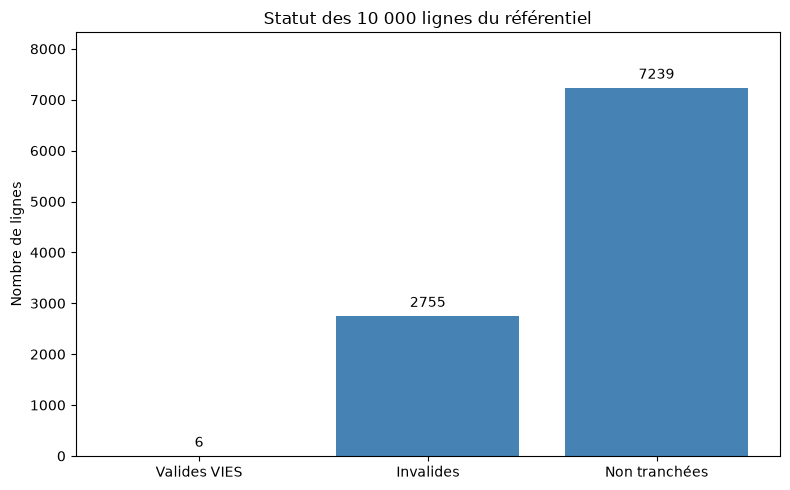

In [57]:
import matplotlib.pyplot as plt
# Compter les lignes par statut
effectifs = reconciliation["statut_final"].value_counts()
effectifs = effectifs.reindex(["valide", "invalide", "non_tranche"])

# Créer le graphique
fig, ax = plt.subplots(figsize=(8, 5))

barres = ax.bar(
    ["Valides VIES", "Invalides", "Non tranchées"],
    effectifs,
    color="steelblue"
)

ax.bar_label(barres, padding=4)
ax.set_title("Statut des 10 000 lignes du référentiel")
ax.set_ylabel("Nombre de lignes")
ax.set_ylim(0, effectifs.max() * 1.15)

plt.tight_layout()
fig.savefig(dossier_graphiques / "01_statuts.svg", bbox_inches="tight")
plt.show()


### Motifs des lignes non tranchées

La figure distingue les lignes non interrogées des erreurs du service, des préfixes non couverts et des absences.


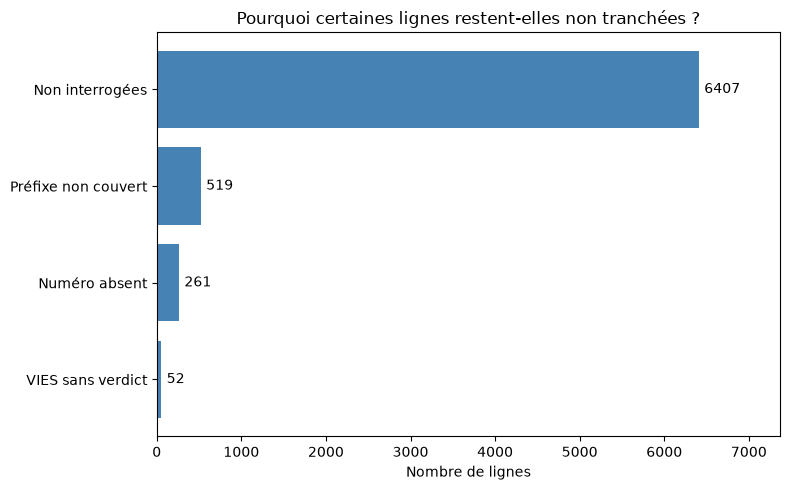

In [58]:
# Garder les lignes non tranchées
non_tranches = reconciliation[
    reconciliation["statut_final"] == "non_tranche"
]

# Compter leurs motifs
motifs = non_tranches["motif_final"].value_counts()

# Remplacer les codes par des libellés lisibles
motifs = motifs.rename(index={
    "non_interroge": "Non interrogées",
    "pays_non_couvert": "Préfixe non couvert",
    "vide": "Numéro absent",
    "vies_non_tranche": "VIES sans verdict"
})

fig, ax = plt.subplots(figsize=(8, 5))

barres = ax.barh(motifs.index, motifs.values, color="steelblue")

ax.bar_label(barres, padding=4)
ax.set_title("Pourquoi certaines lignes restent-elles non tranchées ?")
ax.set_xlabel("Nombre de lignes")
ax.set_xlim(0, motifs.max() * 1.15)
ax.invert_yaxis()

plt.tight_layout()
fig.savefig(dossier_graphiques / "02_non_tranches.svg", bbox_inches="tight")
plt.show()


### Du référentiel aux candidats VIES

Les 6 302 candidats incluent 500 reconstructions proposées. Le nettoyage évite 3 698 appels par rapport à un appel pour chacune des 10 000 lignes. Les étapes ne mesurent pas toutes la même unité : les premières comptent des lignes, puis des numéros uniques.


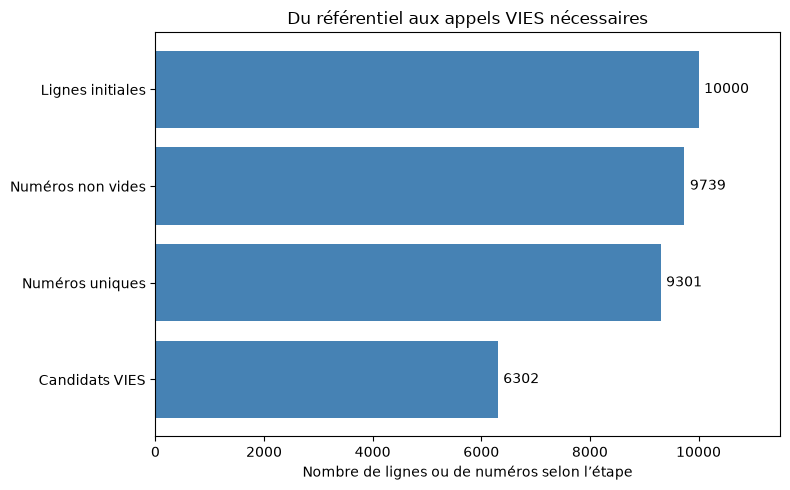

In [59]:
etapes = [
    "Lignes initiales",
    "Numéros non vides",
    "Numéros uniques",
    "Candidats VIES"
]

nombres = [
    len(df),
    len(numeros_non_vides),
    len(numeros_uniques),
    len(candidats_vies)
]

fig, ax = plt.subplots(figsize=(8, 5))

barres = ax.barh(etapes, nombres, color="steelblue")

ax.bar_label(barres, padding=4)
ax.set_title("Du référentiel aux appels VIES nécessaires")
ax.set_xlabel("Nombre de lignes ou de numéros selon l’étape")
ax.set_xlim(0, max(nombres) * 1.15)
ax.invert_yaxis()

plt.tight_layout()
fig.savefig(dossier_graphiques / "03_entonnoir.svg", bbox_inches="tight")
plt.show()


## 4.10 — Conclusion et fichiers de restitution

Le rapport conserve **10 000 lignes** : **6 valides selon VIES, 2 755 invalides en l’état et 7 239 non tranchées**. Il conserve les valeurs brutes, la reconstruction éventuelle, la date VIES, les motifs et les 438 répétitions supplémentaires. Ces comptes portent sur des lignes, pas sur des clients distincts.

L’essentiel des non tranchées provient des numéros non interrogés. Les erreurs du service ne sont pas des preuves d’invalidité. Les reconstructions demeurent des hypothèses, même lorsque le numéro proposé passe les contrôles. Les écarts descriptifs entre groupes ne démontrent pas une cause unique des erreurs.

| Livrable | Emplacement relatif au notebook |
|---|---|
| Rapport détaillé | [rapport_reconciliation.csv](../resultats/rapport_reconciliation.csv) |
| Synthèse des statuts et motifs | [synthese_reconciliation.csv](../resultats/synthese_reconciliation.csv) |
| Trois figures SVG | [Dossier des graphiques](../resultats/graphiques/) |
| Note signée à la direction financière | [note_direction_financiere.md](../resultats/note_direction_financiere.md) |
| Résultats de collecte | [collecte_vies.json](../resultats/collecte_vies.json) |
| Journal de collecte | [collecte_vies.log](../collecte_vies.log) |
| Instructions de lancement | [README](../README.md) |

Les suites proposées sont la confirmation des données douteuses, le réexamen des non tranchés et la priorisation des prochaines factures. Les arbitrages fiscaux, les responsables opérationnels et le calendrier relèvent de la direction financière.

**Limites de remise :** la note conserve trois graphiques agrandis ; sa tenue sur une seule page doit être contrôlée à l’export. La vérification depuis un clone neuf, l’historique de commits et le journal de bord concernent la remise globale du projet et ne sont pas attestés par les seules sorties du notebook.

**Vérification de reproduction :** toutes les cellules ont été exécutées avec succès dans un noyau neuf, depuis le dossier Notebook, en mode archives. Les appels requests.get étaient bloqués pendant ce contrôle. Les rapports CSV et les trois figures ont été régénérés sans nouvel appel VIES. Cette vérification ne remplace pas le test de remise depuis un clone neuf.